In [1]:
%pip install pandas
%pip install numpy
%pip install pyarrow
%pip install scikit-learn
%pip install jinja2
%pip install seaborn


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python3 -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To 

In [32]:
# Libraries needed for import
import pandas as pd
import numpy as np
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler 
from sklearn.model_selection import train_test_split


In [5]:
# Create an empty list to store the data frames
dataframes = []

# Load the dataset
data_folder = "/Users/ashleyfoster/Desktop/fall2026_L"
# Make a list of all the files
all_files = [
    "ids_0.csv",
    "ids_1.csv",
    "ids_2.csv",
    "ids_3.json",
    "ids_4.json",
    "ids_5.parquet",
    "ids_6.parquet",
    "ids_7.json",
    "ids_8.parquet"
]

# Read each file
for file in all_files:

    if file.endswith(".csv"):
        df_temp = pd.read_csv(data_folder + "/" + file)

    elif file.endswith(".json"):
        df_temp = pd.read_json(data_folder + "/" + file, lines=True)

    elif file.endswith(".parquet"):
        df_temp = pd.read_parquet(data_folder + "/" + file)

    # Add the original filename
    df_temp["source_file"] = file

    # Store the DataFrame
    dataframes.append(df_temp)

    print(file, ":", df_temp.shape)

# Combine all data frames
df = pd.concat(dataframes, ignore_index=True)

# Display dimensions
print("\nCombined dataset shape:", df.shape)

ids_0.csv : (1001, 80)
ids_1.csv : (1001, 80)
ids_2.csv : (1001, 80)
ids_3.json : (1001, 80)
ids_4.json : (1001, 80)
ids_5.parquet : (15001, 80)
ids_6.parquet : (5001, 80)
ids_7.json : (9000, 80)
ids_8.parquet : (10293, 80)

Combined dataset shape: (44300, 80)


In [6]:
# Remove leading and trailing spaces from column names
df.columns = df.columns.str.strip()

In [7]:
# Show the first 20 rows of the dataset
df.head(20)

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,443,300491,7,5,376,3508,201,0,53.714286,78.686539,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
1,37218,21,2,1,0,0,0,0,0.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
2,53,176,2,2,148,212,74,74,74.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
3,53,218,2,2,108,330,54,54,54.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
4,53,30753,2,2,70,126,35,35,35.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
5,443,125676,9,5,506,3743,204,0,56.222222,79.452467,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
6,123,16306,1,1,48,48,48,48,48.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
7,56434,2242,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv
8,443,5659933,9,6,380,4091,187,0,42.222222,75.935462,...,256058.0,0.0,256058,256058,5403872.0,0.0,5403872,5403872,BENIGN,ids_0.csv
9,39080,214,3,1,31,6,31,0,10.333333,17.897858,...,0.0,0.0,0,0,0.0,0.0,0,0,BENIGN,ids_0.csv


In [8]:
# Check the data types
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 44300 entries, 0 to 44299
Data columns (total 80 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   Destination Port             44300 non-null  int64  
 1   Flow Duration                44300 non-null  int64  
 2   Total Fwd Packets            44300 non-null  int64  
 3   Total Backward Packets       44300 non-null  int64  
 4   Total Length of Fwd Packets  44300 non-null  int64  
 5   Total Length of Bwd Packets  44300 non-null  int64  
 6   Fwd Packet Length Max        44300 non-null  int64  
 7   Fwd Packet Length Min        44300 non-null  int64  
 8   Fwd Packet Length Mean       44300 non-null  float64
 9   Fwd Packet Length Std        44300 non-null  float64
 10  Bwd Packet Length Max        44300 non-null  int64  
 11  Bwd Packet Length Min        44300 non-null  int64  
 12  Bwd Packet Length Mean       44300 non-null  float64
 13  Bwd Packet Length Std      

In [9]:
# Ignore source_file while checking for duplicates
columns_to_check = df.columns.drop("source_file")

# Count the duplicate number of records
print("Duplicate rows:", df.duplicated(subset=columns_to_check).sum())

# Count all rows that are part of a duplicate group, including the first occurrence
print("Rows included in duplicate groups:", df.duplicated(subset=columns_to_check, keep=False).sum())

Duplicate rows: 6987
Rows included in duplicate groups: 7328


In [10]:
# Remove duplicate records and keep the first occurrence
df_clean = df.drop_duplicates(subset=columns_to_check).copy()

# Display results
print("Original dataset:", df.shape)
print("Cleaned dataset:", df_clean.shape)
print("Duplicates remaining:", df_clean.duplicated(subset=columns_to_check).sum())

Original dataset: (44300, 80)
Cleaned dataset: (37313, 80)
Duplicates remaining: 0


In [11]:
# Check for missing values
missing_values = df_clean.isna().sum()

# Display only columns that contain missing values
print(missing_values[missing_values > 0])

Flow Bytes/s      7
Flow Packets/s    3
dtype: int64


In [12]:
# Identify rows containing missing values
missing_rows = df_clean[df_clean.isna().any(axis=1)]

# Display the number of affected rows
print("Rows with missing values:", len(missing_rows))

# Display the affected classes
print("\nClasses affected by missing values:")
print(missing_rows["Label"].value_counts())

Rows with missing values: 7

Classes affected by missing values:
Label
DoS Hulk    4
BENIGN      3
Name: count, dtype: int64


In [13]:
# Drop rows with missing values
df_clean = df_clean.dropna().copy()

# Display the results of removing the missing values
print("Dataset after removing missing values:", df_clean.shape)
print("Remaining missing values:", df_clean.isna().sum().sum())

Dataset after removing missing values: (37306, 80)
Remaining missing values: 0


In [14]:
# Combine all DoS attack types into the attack category
df_clean["Label"] = df_clean["Label"].replace({"DoS GoldenEye": "attack", "DoS Hulk": "attack", "DoS slowhttptest": "attack", "DoS slowloris": "attack"})

# Rename BENIGN to benign
df_clean["Label"] = df_clean["Label"].replace({"BENIGN": "benign"})

In [15]:
# Convert labels into numerical values
df_clean["Label"] = df_clean["Label"].map({"attack": 1,"benign": 0})

# Display the class distribution
print(df_clean["Label"].value_counts())

Label
1    32352
0     4954
Name: count, dtype: int64


In [16]:
# Display the final dataset dimensions
print("Final dataset shape:", df_clean.shape)

# Display the first five rows
display(df_clean.head())

Final dataset shape: (37306, 80)


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,443,300491,7,5,376,3508,201,0,53.714286,78.686539,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
1,37218,21,2,1,0,0,0,0,0.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
2,53,176,2,2,148,212,74,74,74.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
3,53,218,2,2,108,330,54,54,54.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
4,53,30753,2,2,70,126,35,35,35.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv


In [17]:
# Save the cleaned dataset as a CSV file
df_clean.to_csv("IDS_cleaned.csv", index=False)

In [18]:
# Load the cleaned CSV file
IDS_cleaned_csv = pd.read_csv("IDS_cleaned.csv")

In [19]:
# Display the size of the dataset
print("Loaded dataset shape:", IDS_cleaned_csv.shape)

# Display the number of records in each class
print("\nClass distribution:")
print(IDS_cleaned_csv["Label"].value_counts())

# Display the first 20 rows
display(IDS_cleaned_csv.head(20))

Loaded dataset shape: (37306, 80)

Class distribution:
Label
1    32352
0     4954
Name: count, dtype: int64


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
0,443,300491,7,5,376,3508,201,0,53.714286,78.686539,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
1,37218,21,2,1,0,0,0,0,0.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
2,53,176,2,2,148,212,74,74,74.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
3,53,218,2,2,108,330,54,54,54.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
4,53,30753,2,2,70,126,35,35,35.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
5,443,125676,9,5,506,3743,204,0,56.222222,79.452467,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
6,123,16306,1,1,48,48,48,48,48.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
7,56434,2242,2,0,12,0,6,6,6.000000,0.000000,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
8,443,5659933,9,6,380,4091,187,0,42.222222,75.935462,...,256058.0,0.0,256058,256058,5403872.0,0.0,5403872,5403872,0,ids_0.csv
9,39080,214,3,1,31,6,31,0,10.333333,17.897858,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv


In [20]:
IDS_cleaned_csv.describe()
#displays the statistics of each column

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/core/nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/core/nanops.py:1324: RuntimeWarning: invalid value encountered in subtract
  sqr = (avg - values) ** 2


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,min_seg_size_forward,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
count,37306.000000,3.730600e+04,37306.000000,37306.000000,37306.000000,3.730600e+04,37306.000000,37306.000000,37306.000000,37306.000000,...,37306.000000,3.730600e+04,3.730600e+04,3.730600e+04,3.730600e+04,3.730600e+04,3.730600e+04,3.730600e+04,3.730600e+04,37306.000000
mean,1192.239372,5.208836e+07,6.602557,5.663057,432.966815,9.846610e+03,299.355224,3.158205,60.322847,120.703250,...,27.738165,7.022763e+04,1.351593e+04,8.694171e+04,6.120755e+04,4.910865e+07,5.948290e+05,4.953624e+07,4.868015e+07,0.867206
std,7308.027224,4.409656e+07,90.742994,122.167763,2252.356680,2.819773e+05,330.191771,17.119921,86.428191,129.853471,...,5.822009,5.244162e+05,2.256535e+05,6.521879e+05,4.852344e+05,4.453023e+07,5.765997e+06,4.477937e+07,4.465873e+07,0.339356
min,0.000000,0.000000e+00,1.000000,0.000000,0.000000,0.000000e+00,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000
25%,80.000000,5.129589e+06,3.000000,2.000000,280.000000,3.440000e+02,237.000000,0.000000,38.000000,81.744441,...,20.000000,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,1.000000
50%,80.000000,6.862321e+07,6.000000,6.000000,351.000000,1.159500e+04,339.000000,0.000000,51.500000,131.652067,...,32.000000,8.380000e+02,0.000000e+00,8.380000e+02,8.340000e+02,5.820000e+07,0.000000e+00,6.515000e+07,4.900000e+07,1.000000
75%,80.000000,9.838480e+07,8.000000,6.000000,394.000000,1.159500e+04,373.000000,0.000000,70.000000,157.992052,...,32.000000,2.003000e+03,0.000000e+00,2.003000e+03,2.002000e+03,9.830000e+07,0.000000e+00,9.830000e+07,9.830000e+07,1.000000
max,63276.000000,1.199919e+08,17487.000000,23539.000000,278248.000000,5.440000e+07,20440.000000,1472.000000,4352.085714,5185.441640,...,60.000000,1.420000e+07,1.010000e+07,2.630000e+07,1.370000e+07,1.200000e+08,6.080000e+07,1.200000e+08,1.200000e+08,1.000000


In [21]:
# Check for infinite values per column
print("Infinite values per column:")
print(np.isinf(IDS_cleaned_csv.select_dtypes(include=np.number)).sum()[
    np.isinf(IDS_cleaned_csv.select_dtypes(include=np.number)).sum() > 0
])

# Find rows containing infinite values
infinite_rows = IDS_cleaned_csv[
    np.isinf(IDS_cleaned_csv.select_dtypes(include=np.number)).any(axis=1)
]

# Display the number of affected rows
print("\nRows containing infinite values:", len(infinite_rows))

# Display the affected rows
display(infinite_rows)

Infinite values per column:
Flow Bytes/s      5
Flow Packets/s    5
dtype: int64

Rows containing infinite values: 5


,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,source_file
522,80,0,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_0.csv
1065,48689,0,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_1.csv
1756,55969,0,2,0,12,0,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_1.csv
2031,50810,0,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_2.csv
2861,443,0,1,1,6,6,6,6,6.0,0.0,...,0.0,0.0,0,0,0.0,0.0,0,0,0,ids_2.csv


In [22]:
# Replace infinite values with NaN
IDS_cleaned_csv = IDS_cleaned_csv.replace([np.inf, -np.inf], np.nan)

# Remove rows containing infinite values
IDS_cleaned_csv = IDS_cleaned_csv.dropna().copy()

# Display the updated dataset dimensions
print("Dataset shape after removing infinite values:", IDS_cleaned_csv.shape)

# Confirm no infinite values remain
print("Remaining infinite values:",
      np.isinf(IDS_cleaned_csv.select_dtypes(include=np.number)).sum().sum())

Dataset shape after removing infinite values: (37301, 80)
Remaining infinite values: 0


In [23]:
IDS_cleaned_csv.iloc[:, :-1].var()
#this finds the variance of the all the columns but the last one since it contains strings

Destination Port               5.320743e+07
Flow Duration                  1.944404e+15
Total Fwd Packets              8.235391e+03
Total Backward Packets         1.492696e+04
Total Length of Fwd Packets    5.073766e+06
                                   ...     
Idle Mean                      1.982884e+15
Idle Std                       3.325113e+13
Idle Max                       2.005132e+15
Idle Min                       1.994352e+15
Label                          1.150772e-01
Length: 79, dtype: float64

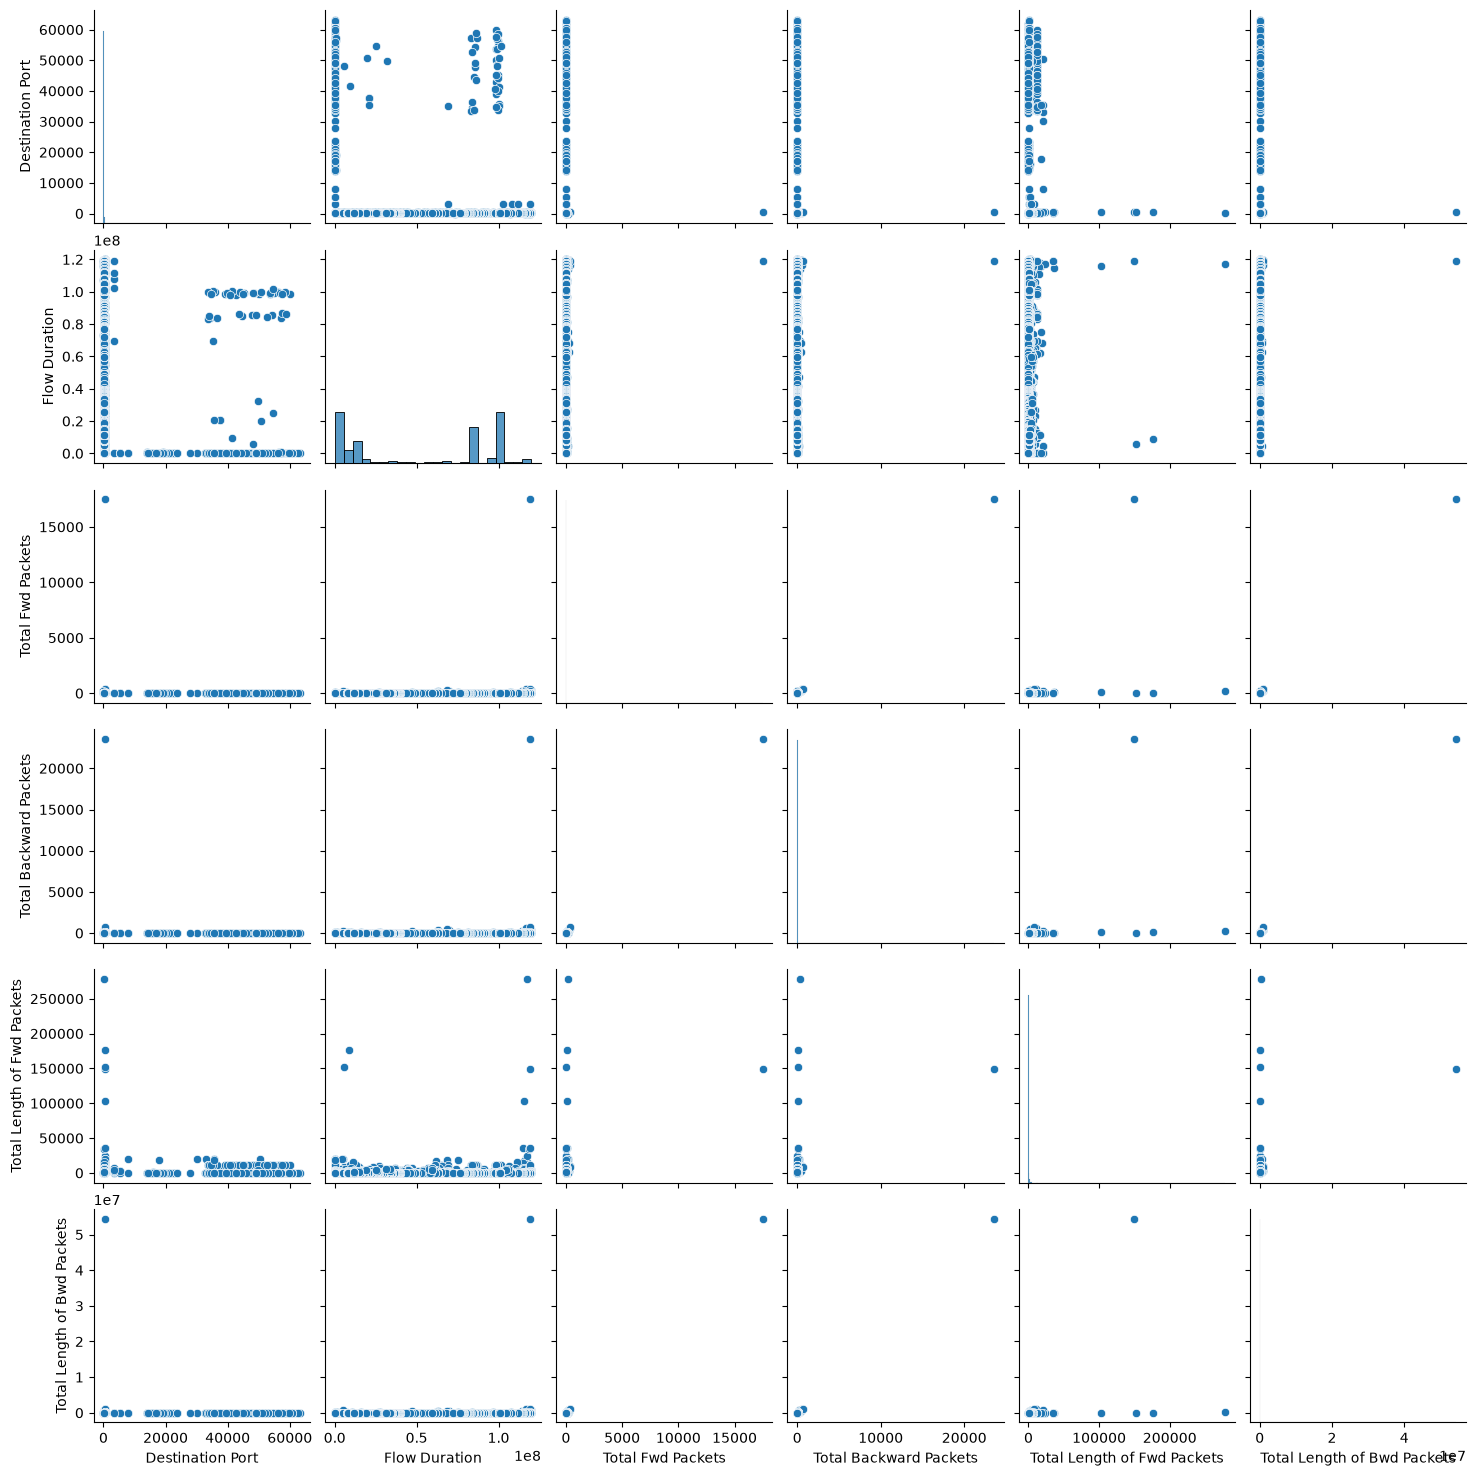

In [24]:
plot = sns.pairplot(IDS_cleaned_csv, vars = ["Destination Port", "Flow Duration", "Total Fwd Packets", 
                                             "Total Backward Packets", "Total Length of Fwd Packets",
                                              "Total Length of Bwd Packets" ])

#creates a pairplot for the first 6 columns of the dataframe
print(plot)
#displays the pairplot

In [25]:
(pd.DataFrame(IDS_cleaned_csv.iloc[:, 0:6])
 .corr()
 .style
 .background_gradient(cmap='coolwarm')
)#creates a correlation matrix of the first 6 columns of the df

,Destination Port,Flow Duration,Total Fwd Packets,Total Backward Packets,Total Length of Fwd Packets,Total Length of Bwd Packets
Destination Port,1.000000,-0.163166,-0.007152,-0.005309,0.022567,-0.004950
Flow Duration,-0.163166,1.000000,0.022532,0.020463,0.041074,0.018685
Total Fwd Packets,-0.007152,0.022532,1.000000,0.999378,0.360820,0.999147
Total Backward Packets,-0.005309,0.020463,0.999378,1.000000,0.360880,0.999542
Total Length of Fwd Packets,0.022567,0.041074,0.360820,0.360880,1.000000,0.349670
Total Length of Bwd Packets,-0.004950,0.018685,0.999147,0.999542,0.349670,1.000000


In [26]:
IDS_cleaned_csv["Label"].nunique()
#determining the unique classes within the labels for the k-means clustering

2

In [27]:
df_to_numpy = IDS_cleaned_csv.iloc[:, :-1].to_numpy()
new_ids = IDS_cleaned_csv.iloc[:, :-1]
print(new_ids.columns[np.isinf(new_ids).any()])

Index([], dtype='str')


In [ ]:
df_to_numpy = IDS_cleaned_csv.iloc[:, :-1].to_numpy()
#converts the df to a numpy array
IDS_standardized = StandardScaler().fit_transform(df_to_numpy)
#standardizes the data in the cleaned dataset
clustered = KMeans(n_clusters=2)
clustered.fit(IDS_standardized)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",2
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",'auto'
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",300
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",None
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](2, 79)"

In [ ]:
X = IDS_cleaned_csv.drop(columns = ["Label", "source_file"])
#splits the cleaned df into features, dropping the label column and the source_file column
y = IDS_cleaned_csv["Label"]
#creates a df with just the target column


In [31]:
features = X.to_numpy()
target = y.to_numpy()
#converts the newly created df into numpy arrays for standardization

features = StandardScaler().fit_transform(features)
#standardizes the input features df for training


In [35]:
X_train, X_test, y_train, y_test = train_test_split(features, target,
                                                                    test_size=0.20,
                                                                    random_state=1,
                                                                    stratify= target)
#Splits the features and target df into training and test dataset with the standard 20% test
#and 80% training
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)
#displays the newly created datasets

(29840, 78)
(7461, 78)
(29840,)
(7461,)
